# Chapter 4 (part 5) — Polynomial, Spline, and Generalized Additive Models

Covers: Polynomial and Spline Regression → Generalized Additive Models (GAM), on Ames Housing.

The thread: **"linear regression" means linear in the *coefficients*, not in the raw variables.** Feed it `x²`, `log(x)`, or bendy basis functions and it's still ordinary least squares. The only real question is how much flexibility to allow: too little misses real curvature (bias), too much chases noise (variance). Polynomials bend *globally*, so the tails go wild. Splines bend *locally*, in pieces joined smoothly at knots. A GAM gives each predictor its own spline and adds them up.

Tooling: polynomials via `I(x**2)` in `smf.ols`; splines via patsy `bs()` / `cr()` in formulas; GAMs via `statsmodels.gam.api.GLMGam` + `BSplines` (no `pygam` here).

**How to work each section** (~10 min each; ~1 hour total with the exam): write your one-line prediction in the *Prediction* cell **before** running anything, do the code, then write 2-3 bullets on where the result matched or broke your prediction and why. Ask for a hint if you get stuck.

In [24]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
import plotly.express as px
import matplotlib.pyplot as plt
from patsy import dmatrix
from statsmodels.gam.api import GLMGam, BSplines
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import mean_squared_error
pd.set_option("display.max_columns", None)

from mlstats.data import load_ames
ames = load_ames()
ames.shape

(2930, 81)

## 1. Polynomial Regression

A quadratic adds an `x²` column: `y ≈ b0 + b1*x + b2*x²`, so the slope is no longer constant. Numeric picture: with `b1 = 100` and `b2 = 0.02`, one more unit of x is worth about `100 + 2*0.02*x`: $140 at x = 1,000 and $180 at x = 2,000. `b1` alone is just the slope at x = 0, which may be far outside your data.

Another trap: `Year_Built` is around 1,950, so `Year_Built²` is around 3.8 million and the two columns are almost perfectly correlated. Centering first (`x - x.mean()`) removes most of that without changing the fitted curve.

**Predict first:** will centering change the fitted values? Will an extra year of newness be worth more in 1920 or in 2000?

**Question 1.** (a) Fit `Sale_Price ~ Year_Built + I(Year_Built**2)` raw and with a centered `Year_Built`. Compare the coefficient tables and confirm the fitted values are identical. (b) From the centered model, compute the marginal effect of one more year at 1920, 1960, and 2000. Where does the curve turn?

*Tools for this question:*
- `I(x**2)` inside the formula protects the arithmetic; centered version: create `df["yb_c"] = df["Year_Built"] - df["Year_Built"].mean()` first.
- Marginal effect of a quadratic `b1*x + b2*x**2` is `b1 + 2*b2*x`; get the values with `res.params[...]`.

_Prediction (one line, before running anything):_
* I believe that centering will change the values since it changes the reference from a house with x = 0 to an average home.
* I predict that an etra year of newness will be worth more in 2000.

In [25]:
# raw model
year_built_raw_model = smf.ols("Sale_Price ~ Year_Built + I(Year_Built**2)", data = ames).fit()
print("Coefficients")
print(year_built_raw_model.params)
print("\nFitted Values")
print(year_built_raw_model.fittedvalues)


Coefficients
Intercept             8.395358e+07
Year_Built           -8.689726e+04
I(Year_Built ** 2)    2.251841e+01
dtype: float64

Fitted Values
0       141685.569406
1       143083.003982
2       139025.810730
3       154126.077125
4       223385.174415
            ...      
2925    187654.163033
2926    185220.881473
2927    208741.741222
2928    165348.004579
2929    211580.354210
Length: 2930, dtype: float64


In [26]:
# centered model
ames_centered = ames.copy()
ames_centered["Centered_Year_Built"] = ames_centered["Year_Built"] - ames_centered["Year_Built"].mean()
year_built_centered_model = smf.ols("Sale_Price ~ Centered_Year_Built + I(Centered_Year_Built**2)", data = ames_centered).fit()
print("Coefficients")
print(year_built_centered_model.params)
print("\nFitted Values")
print(year_built_centered_model.fittedvalues)

Coefficients
Intercept                      160203.655613
Centered_Year_Built              1886.368493
I(Centered_Year_Built ** 2)        22.518413
dtype: float64

Fitted Values
0       141685.569321
1       143083.003897
2       139025.810645
3       154126.077039
4       223385.174329
            ...      
2925    187654.162947
2926    185220.881388
2927    208741.741136
2928    165348.004494
2929    211580.354124
Length: 2930, dtype: float64


In [27]:
# marginal effect
test_years = [1920, 1921, 1960, 1961, 2000, 2001]
centered_years = test_years - ames_centered["Year_Built"].mean()
print(centered_years)
new_houses = pd.DataFrame({
    'Centered_Year_Built': centered_years 
})

predicted_prices = pd.DataFrame(year_built_centered_model.predict(new_houses))
predicted_prices = predicted_prices.rename(columns={0:"Predicted_Values"})
predicted_prices["Dollar_Change"] = predicted_prices['Predicted_Values'].diff()
predicted_prices.loc[predicted_prices.index % 2 == 0, "Dollar_Change"] = pd.NA

predicted_prices


[-51.35631399 -50.35631399 -11.35631399 -10.35631399  28.64368601
  29.64368601]


,Predicted_Values,Dollar_Change
0,122718.383079,NaN
1,122314.344641,-404.038439
2,141685.569321,NaN
3,143083.003897,1397.434576
4,232711.676148,NaN
5,235910.583739,3198.907591


In [28]:
ames_centered["Year_Built"].mean()

np.float64(1971.3563139931741)

**Where Does The Curve Turn?**

**The fitted curve (centered model):** price ≈ 160,204 + 1,886·x + 22.5·x², where x = Year_Built − 1971.4 (the average year). So x = 0 is an average-age house, x = −50 is about 1921, and x = +29 is about 2000.

**What "marginal effect" means:** how much the predicted price changes for one more year of newness. Because of the x² term it isn't one number. Worked check from x = 10 to x = 11: price goes 181,319 → 183,679, a change of **+$2,359**. The linear part always adds 1,886; the squared part adds 22.5 × (11² − 10²) = 22.5 × 21 ≈ 473 more, and 21 is about 2 × 10.5. That is where the shortcut comes from:

> **marginal effect ≈ b1 + 2·b2·x = 1,886 + 45·x** (use the *centered* x, not the raw year)

| Year | centered x | marginal effect (formula) | one-year price change (my table) |
|---|---|---|---|
| 1920 | −51.4 | about **−$427** per year | −$404 (1920 to 1921) |
| 1960 | −11.4 | about **+$1,375** per year | +$1,397 |
| 2000 | +28.6 | about **+$3,176** per year | +$3,199 |

(The formula gives the slope at exactly that year, and the table gives the change over the next full year, so they differ slightly.)

**Where it turns:** the turning point is where the marginal effect crosses zero (the bottom of the U): 1,886 + 45·x = 0, so x = −1,886 / 45 ≈ −41.9, i.e. about 42 years below the average, which is **1971.4 − 41.9 ≈ 1929**.
* Before about 1929, one more year of newness goes with a *lower* price (older homes carry a premium); after it, each extra year is worth more, and more and more over time.
* Caution: only about 370 of the 2,930 homes were built before 1930, so the left side of the curve rests on much less data than the right side.
* Summary: a 1920-to-1921 step lowers the predicted price, and the 2000-to-2001 step raises it the most.

_What matched, what surprised you, and why (2-3 bullets):_
* **Coefficients vs. fitted values.** I predicted the centered model would "change the values". The coefficients did change (the Year_Built slope and the intercept: the intercept is now the predicted price at the average year, 1971), but the quadratic coefficient (22.5) stayed the same because it measures curvature, and shifting x doesn't change curvature. The fitted values were also identical, which I had predicted wrongly: centering only changes the reference point (a year of 0 vs. the average year), not the curve itself.
* **Why the fitted values are the same.** Both models describe the same curve and predict the same y for each house. The raw model takes the year built as the input, and the centered model takes how many years newer or older than average the house is.
* **Newness is worth more in 2000, as I predicted.** One more year of newness is worth about +$3,176 at 2000 versus about −$427 at 1920. The curve turns at about 1929, with older homes having a price premium and newer ones a rising premium for each year.

## 2. How Flexible Should the Curve Be?

More terms always fit the training data better; the question is held-out performance. Numeric picture: with 5 points, a degree-4 polynomial passes through all of them exactly (zero training error) and swings wildly between them, while a line misses all five a little but stays stable.

**Predict first:** at which degree will CV RMSE bottom out: 1-2, 3-5, or 8+?

**Question 2.** (a) Write a small function `cv_rmse(formula, df)` that returns train RMSE and 5-fold CV RMSE (you'll reuse it in Section 3). Use it on polynomials of standardized `Gr_Liv_Area` for degrees 1, 2, 3, 5, 8, 10 and plot both curves. Which degree would you pick? (b) Plot the degree 2, 5, and 10 fits over `Gr_Liv_Area` from 300 to 7,000 (the data max is 5,642). What happens at the edges and beyond?

*Tools for this question:*
- `KFold(n_splits=5, shuffle=True, random_state=0).split(df)` yields `(train_idx, test_idx)` arrays; use `df.iloc[idx]`.
- Degree-k formula: `"Sale_Price ~ " + " + ".join(["z"] + [f"I(z**{j})" for j in range(2, k + 1)])` where `z` is the standardized column `(x - x.mean()) / x.std()`.

_Prediction (one line, before running anything):_
* I think RMSE will bottom out around the 3-5 degrees range. Too many degrees could overfit to training and then too little generalizes poorly.

In [29]:
def cv_rmse(formula, df):

    # Training RMSE
    full_model = smf.ols(formula, data=df).fit()
    train_predictions = full_model.predict(df)

    train_rmse = np.sqrt(
        mean_squared_error(df['Sale_Price'], train_predictions)
    )

    # 5-fold CV RMSE
    kf = KFold(n_splits=5, shuffle=True, random_state=0).split(df)
    scores = []

    for train_idx, test_idx in kf:

        train = df.iloc[train_idx]
        test = df.iloc[test_idx]

        model = smf.ols(formula, data=train).fit()
        predictions = model.predict(test)

        rmse = np.sqrt(
            mean_squared_error(test['Sale_Price'], predictions)
        )

        scores.append(rmse)

    return train_rmse, np.mean(scores)


In [30]:
ames["z"] = (
    ames["Gr_Liv_Area"] - ames["Gr_Liv_Area"].mean()
) / ames["Gr_Liv_Area"].std()

train_rmse_list = []
cv_rmse_list = []

for k in range(1,11):

    formula = "Sale_Price ~ " + " + ".join(
        ["z"] + [f"I(z**{j})" for j in range(2, k + 1)]
    )

    train_rmse, cv_score = cv_rmse(formula, ames)
    train_rmse_list.append(train_rmse)
    cv_rmse_list.append(cv_score)

    print(f"Degree {k}: Train RMSE = {train_rmse:.2f}, CV RMSE = {cv_score:.2f}")



Degree 1: Train RMSE = 56504.88, CV RMSE = 56537.57
Degree 2: Train RMSE = 56135.38, CV RMSE = 56664.62
Degree 3: Train RMSE = 55469.61, CV RMSE = 55804.51
Degree 4: Train RMSE = 55303.03, CV RMSE = 56200.46
Degree 5: Train RMSE = 55300.85, CV RMSE = 58463.04
Degree 6: Train RMSE = 55272.82, CV RMSE = 63704.53
Degree 7: Train RMSE = 55092.20, CV RMSE = 64086.24
Degree 8: Train RMSE = 55032.59, CV RMSE = 69192.14
Degree 9: Train RMSE = 55017.77, CV RMSE = 195258.12
Degree 10: Train RMSE = 54982.24, CV RMSE = 460471.74


In [31]:
# plot degrees vs train RMSE
fig = px.line(x = [k for k in range(1,11)], y = train_rmse_list, title = "Polynomial Degree vs. Training RMSE", markers=True, labels={"x": "Polynomial Degree (k)", "y": "Training RMSE (Error)"} )
fig.show()

# plot degrees vs CV RMSE
fig_2 = px.line(x = [k for k in range(1,11)], y = cv_rmse_list, title = "Polynomial Degree vs. CV RMSE", markers=True, labels={"x": "Polynomial Degree (k)", "y": "CV RMSE (Error)"})
fig_2.show()

**Which Degree Would You Pick?**
* **Pick degree 3** (or degree 1 if you want the simplest model). Degree 3 has the lowest CV RMSE, **55.8k**. Degree 7 is 64.1k, about 15% worse.
* Train RMSE only falls from 56.5k (degree 1) to 55.0k (degree 10), about 3%, so extra terms buy almost nothing on the data the model has seen.
* CV RMSE is flat for degrees 1 to 4 (56.5k, 56.7k, 55.8k, 56.2k), so degrees 1 and 3 are within about 1% of each other. When models tie, take the simpler one.
* From degree 5 on, CV rises (58.5k, 63.7k, 64.1k, 69.2k, then 195k and 460k). That growing gap between train and CV is overfitting.

In [32]:
# living space grid (generate 200 numbers between 300 to 7000) these are what we are going to predict on and force the model to extrapolate a bit
living_space_grid = np.linspace(300,7000,200)
z_grid = (living_space_grid - ames["Gr_Liv_Area"].mean()) / ames["Gr_Liv_Area"].std()
grid_df = pd.DataFrame({"z": z_grid})

frames = []

# refit degree 2, 5, 10 on all ames
for k in [2,5,10]:
    # fit
    model = smf.ols("Sale_Price ~ " + " + ".join(
        ["z"] + [f"I(z**{j})" for j in range(2, k + 1)]
    ), data = ames).fit()

    # predict
    pred = model.predict(grid_df)

    # small dataframe
    frames.append(pd.DataFrame({
        "Gr_Liv_Area": living_space_grid,
        "fitted": pred,       # the predictions from this model
        "degree": str(k),      # same label repeated on every row
    }))

curves = pd.concat(frames, ignore_index=True)


In [33]:
# plot fitted vs real values
fig = px.line(curves, x="Gr_Liv_Area", y="fitted", color="degree")
fig.show()


**What Happens At The Edges and Beyond**
* **Bottom edge (300 sqft):** the curves already disagree. Degree 2 gives about 24k, degree 5 about 40k, and degree 10 is negative (**-56k**). Few homes live here, so the high-degree curve is free to swing.
* **Inside the data, near the top:** degree 10 breaks before the data ends. At 5,000 sqft it predicts about 195k, versus about 380k for degree 5. Only 5 homes are above 4,000 sqft, so the fit follows those few points.
* **Beyond 5,642 sqft:** degree 5 goes negative (about -193k at 6,000 sqft), and degree 10 collapses to about -1.7M at 6,000 sqft. Degree 2 stays positive but just flattens at about 480k, which is not a good forecast either.
* **Why:** a polynomial is one formula for the whole x-axis, so a wiggle needed to fit a few points in one region changes the curve everywhere, and the highest power takes over once x is outside the data. Splines (next section) fix this by making each piece local.

_What matched, what surprised you, and why (2-3 bullets):_
* **Matched:** I predicted CV RMSE would bottom out in the 3-5 bucket, and it bottomed out at **degree 3** (55.8k). The prediction was right.
* **Surprised:** how flat it is from degree 1 to 4 (about 56k). The curve is not really a U-shape with a sharp minimum. It is a plateau, then a climb starting at degree 5, and a blow-up at degrees 9 and 10 (195k and 460k).
* **Why:** price vs living area is close to a straight line plus a mild bend, so degree 1 to 3 already capture the signal. Extra powers can only chase noise and the few huge homes, which helps train error slightly and hurts held-out error a lot.

## 3. Splines

A **spline** cuts the x-axis into pieces at **knots** and fits a separate cubic in each piece, constrained to join smoothly. Numeric picture: knots at 1,000 and 2,000 sqft give three cubics that share the same value, slope, and curvature where they meet. A change in shape above 2,000 doesn't disturb the fit below 1,000, which is the key difference from a polynomial. The **degrees of freedom** (`df`, the number of basis columns) is the flexibility knob. A **natural** spline (`cr`) also forces the curve to be straight outside the outer knots, which tames the tails.

**Predict first:** past 4,000 sqft, which will behave more sensibly, `bs(df=6)` or `cr(df=6)`?

**Question 3.** (a) With `Gr_Liv_Area` as the only predictor, fit `bs(..., df=k)` for k = 4, 6, 12 and `cr(..., df=6)`, and plot them together. Compare `bs` and `cr` past 4,000 sqft. (b) Reuse your `cv_rmse` function (just swap the formula) to compare the best polynomial from Section 2 with `bs` at df 4, 6, 8, 12.

*Tools for this question:*
- `bs(x, df=6, degree=3, lower_bound=lo, upper_bound=hi)` B-spline basis; `cr(x, df=6)` natural cubic spline.
- **Gotcha:** `bs()` can't predict outside the range it was fit on (`Gr_Liv_Area` runs 334 to 5,642). Plot over `np.linspace(col.min(), col.max(), 200)` instead of the 300-7,000 grid from Section 2, or pass `lower_bound` / `upper_bound`; inside CV, compute the bounds from the *full* column.
- Use `cr(x, df=6, constraints="center")`: without it the `cr` columns duplicate the intercept and statsmodels warns that the design matrix is rank-deficient.

_Prediction (one line, before running anything):_
* It seems like bs() handles more about how the different knots fits on data within a specified range where data points are more abundant while cr() talks more about how the spline forces the curve to be straight on the outer knots where there are less observations. Homes about 4,000 sq ft are most likely out of the common range where there are a reasonable number of observations leading me to believe that its a value that sits on the tail of the x-axis. So cr() would behave more sensibly.

In [43]:
k_list = [4,6,12]

# grid of values to predict on
living_space_grid = pd.DataFrame({"Gr_Liv_Area" : np.linspace(ames["Gr_Liv_Area"].min(), ames["Gr_Liv_Area"].max(),200)})

frames = []

for k in k_list:
    # fit the 2 models
    model_bs = smf.ols(f"Sale_Price ~ bs(Gr_Liv_Area, df = {k})", data = ames).fit()
    model_cr = smf.ols('Sale_Price ~ cr(Gr_Liv_Area, df=6, constraints="center")', data=ames,).fit()

    # predict on it
    pred_bs = model_bs.predict(living_space_grid)
    pred_cr = model_cr.predict(living_space_grid)
    
    # but poth in a dataframe to plot
    frames.append(pd.DataFrame({
            "Gr_Liv_Area": living_space_grid["Gr_Liv_Area"],
            "bs_fitted": pred_bs,       # the predictions from this model
            "cr_fitted": pred_cr,
            "degree": str(k),      # same label repeated on every row
        }))

cr_bs_df = pd.concat(frames, ignore_index=True)

In [44]:
for k in k_list:
    cr_bs_df_plot = cr_bs_df[cr_bs_df["degree"] == str(k)].copy()

    fig = px.line(cr_bs_df_plot, x ="Gr_Liv_Area", y = ["bs_fitted","cr_fitted"], title = f"Fitted Values for Cr and Bs Model With K = {k}")

    fig.show()

In [47]:
bs_train_rmse_list = []
bs_cv_rmse_list = []
lo, hi = ames["Gr_Liv_Area"].min(), ames["Gr_Liv_Area"].max()

for k in [4,6,8,12]:

    formula = f"Sale_Price ~ bs(Gr_Liv_Area, df={k}, lower_bound={lo}, upper_bound={hi})"

    train_rmse, cv_score = cv_rmse(formula, ames)
    bs_train_rmse_list.append(train_rmse)
    bs_cv_rmse_list.append(cv_score)

    print(f"Degree {k}: Train RMSE = {train_rmse:.2f}, CV RMSE = {cv_score:.2f}")

Degree 4: Train RMSE = 55403.59, CV RMSE = 55732.83
Degree 6: Train RMSE = 55310.57, CV RMSE = 55752.82
Degree 8: Train RMSE = 55258.45, CV RMSE = 55911.67
Degree 12: Train RMSE = 55221.06, CV RMSE = 56111.52


_What matched, what surprised you, and why (2-3 bullets):_
* **Matched:** I predicted `cr()` would behave more sensibly past 4,000 sqft, and it did. Past 4,000 sqft, `bs(df=6)` falls from about 448k (4,000 sqft) to about 145k (5,642 sqft). `cr(df=6)` only drifts from about 389k to about 335k.
* **What the `bs` dive really is:** not 'bigger homes sell for less'. Only 5 homes are above 4,000 sqft: two sold for about 750k and three for 160k-185k (including the 5,642 sqft one). A flexible local cubic chases those few points, and with so little data nothing holds it back. `cr` is forced to be a straight line past the outer knots, so it can't chase them. It still slopes down a little (that is the straight line), but it never collapses.
* **CV comparison:** `bs` CV RMSE is 55.73k (df 4), 55.75k (df 6), 55.91k (df 8), 56.11k (df 12). The best polynomial (degree 3) is 55.80k, so the spline and the polynomial are **essentially tied**. df 4 'wins' by a hair that is within noise, so I would take the simplest. I don't trust train RMSE here because it is measured on the same rows the model was fit on.
* **What does differ is stability as flexibility grows:** at equal flexibility, degree 8 polynomial is 69.19k vs `bs` df 8 at 55.91k, and degree 10 is 460k vs `bs` df 12 at 56.11k. A spline's pieces are local, so extra flexibility stays contained, while a polynomial's terms affect the whole x-axis.

## 4. Generalized Additive Models

A GAM generalizes the idea: `y ≈ b0 + f1(x1) + f2(x2) + b3*x3`, where each `f` is a spline with a **smoothness penalty** `alpha` (bigger alpha = flatter, more line-like curve). The effects still *add*, so you can plot each `f` on its own and read it like a coefficient: "the contribution of living area to price, holding the other terms fixed". The penalty replaces hand-tuning the number of knots: use plenty of knots and let the penalty decide how much wiggle to keep. Numeric picture: with alpha huge, an 8-df spline is forced nearly straight and behaves like a 1-df line; with alpha near 0 it uses all 8 df.

**Predict first:** on a test set, will the GAM's RMSE gain over the straight-line model be small (under ~15%) or large (over ~15%)? Why?

**Question 4.** Make one 70/30 train/test split. On train, fit `GLMGam` with `BSplines` on `Year_Built` and `Gr_Liv_Area` (`df=[8, 8]`, `degree=[3, 3]`), linear terms for `Garage_Area` and `Total_Bsmt_SF`, and `alpha=[1, 1]`. (a) Plot the partial effect of each smooth. Which is closest to straight? (b) Refit with `alpha` at 1e6 and at 1e-3 and re-plot. What happens, and which knob from Sections 2-3 does alpha replace? (c) Compare test RMSE of the `alpha=[1, 1]` GAM to the straight-line OLS on the same four predictors.

*Tools for this question:*
- `bs = BSplines(df[["Year_Built", "Gr_Liv_Area"]], df=[8, 8], degree=[3, 3])` builds the smoothers.
- `GLMGam.from_formula("Sale_Price ~ Garage_Area + Total_Bsmt_SF", data=df, smoother=bs, alpha=[1, 1])` then `.fit()`; `res.plot_partial(i, cpr=True)` plots smooth number `i`.
- Predict on test: `res.predict(test, exog_smooth=xs)`. **Gotcha:** it raises `NotImplementedError` if any test value falls outside the training range, so clip first: `xs = test[cols].clip(lower=train[cols].min(), upper=train[cols].max(), axis=1)`.

_Prediction (one line, before running anything):_
* I believe that GAM's RMSE gain over a straight line model will be over 15%. I believe the GAM has the ability to capture non linear patterns that a straight line may not be able to capture while being able to better generalize on tails with less observations (where I assume the alpha is bigger and the curve is flatter).

In [51]:
# 70/30 train test split
df_train, df_test = train_test_split(ames, test_size=0.3, random_state=42)

# bsplines on year built and gr liv area
bs = BSplines(df_train[["Year_Built", "Gr_Liv_Area"]], df=[8, 8], degree=[3, 3])

# fit with linear terms for garage area and basement sf
GAM_model = GLMGam.from_formula("Sale_Price ~ Garage_Area + Total_Bsmt_SF", data=df_train, smoother=bs, alpha=[1, 1]).fit()


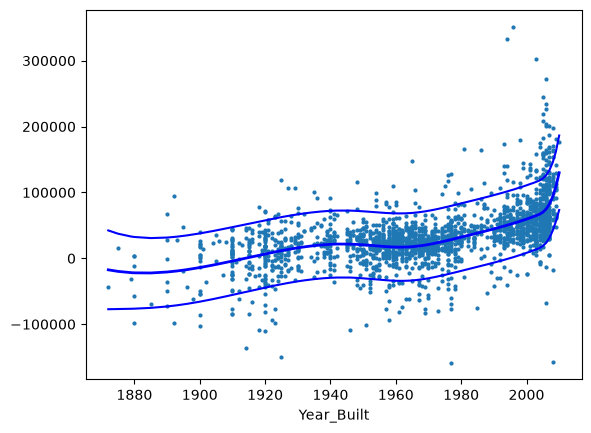

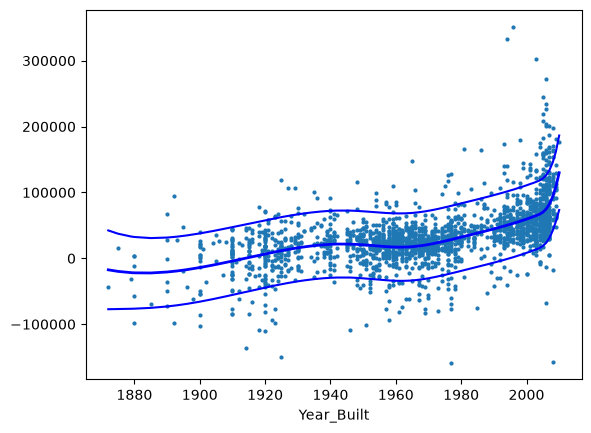

In [55]:
# we have 2 smoothed variables: gr_liv_area and year built. Plot the partial effect of each smooth
GAM_model.plot_partial(0, cpr = True)

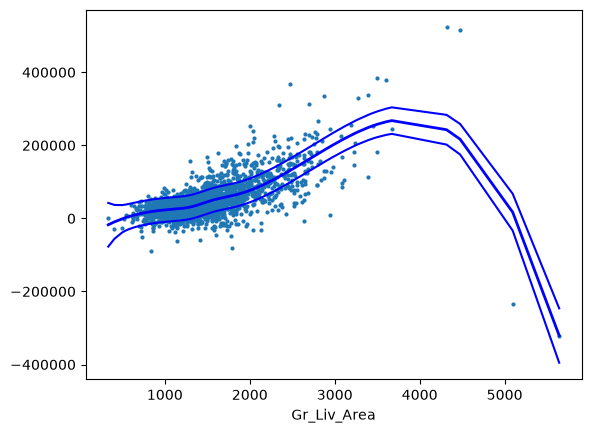

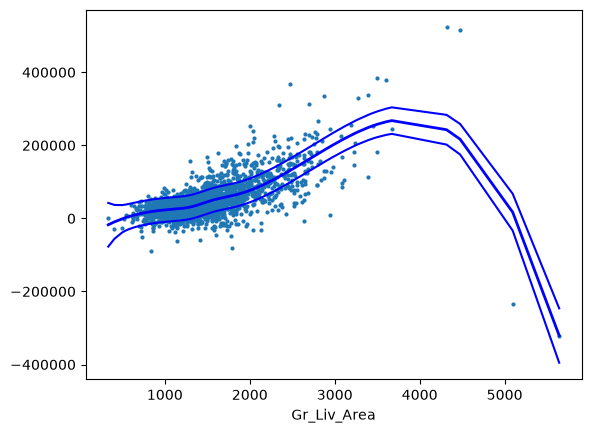

In [56]:
GAM_model.plot_partial(1, cpr = True)

In [57]:
# refit with alpha at 1000000 and 0.001

# fit with linear terms for garage area and basement sf
GAM_alpha_1000000 = GLMGam.from_formula("Sale_Price ~ Garage_Area + Total_Bsmt_SF", data=df_train, smoother=bs, alpha=[1000000, 1000000]).fit()

GAM_alpha_001 = GLMGam.from_formula("Sale_Price ~ Garage_Area + Total_Bsmt_SF", data=df_train, smoother=bs, alpha=[0.001, 0.001]).fit()

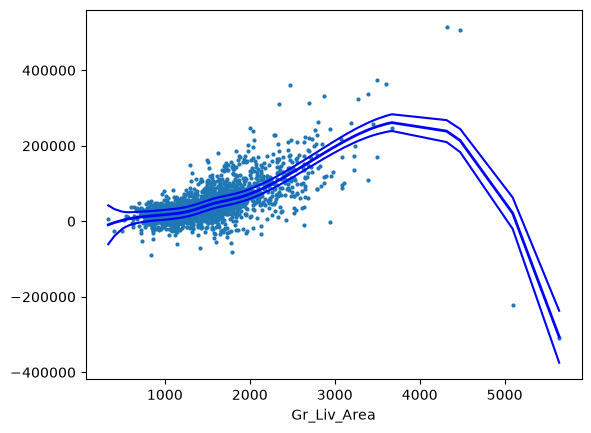

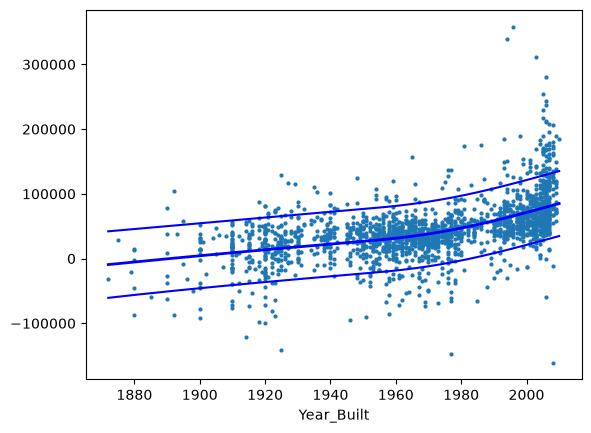

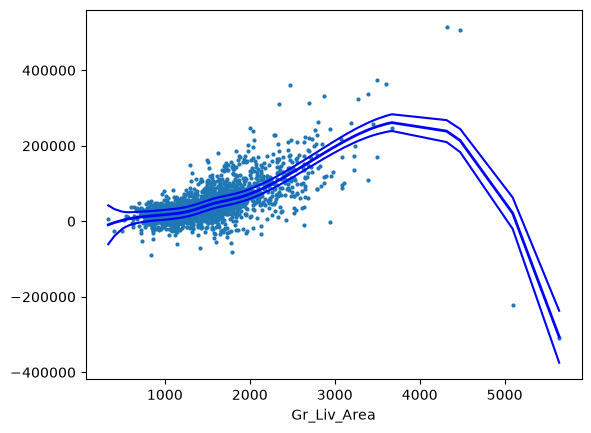

In [58]:
GAM_alpha_1000000.plot_partial(0, cpr = True)
GAM_alpha_1000000.plot_partial(1, cpr = True)

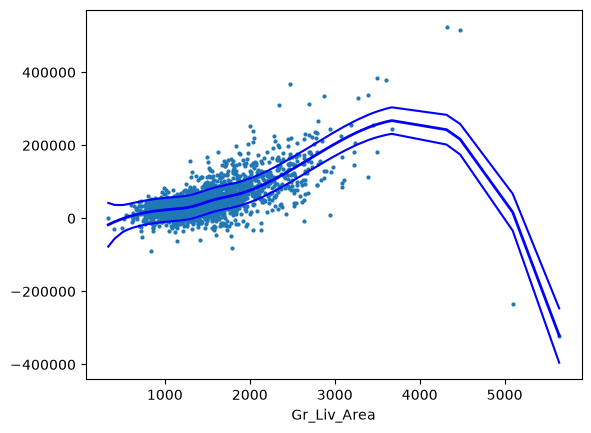

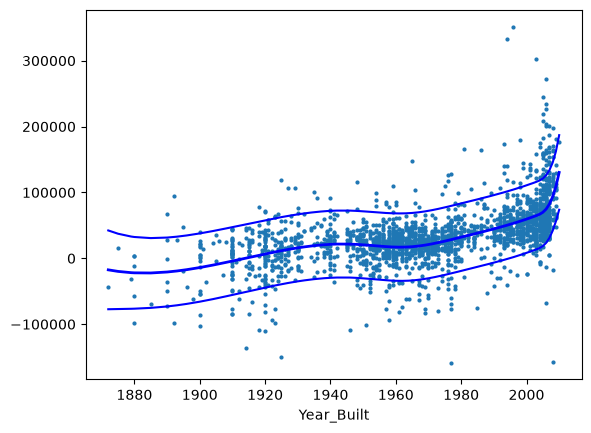

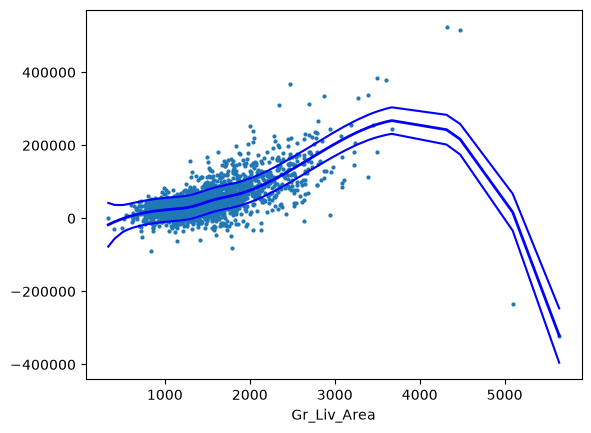

In [59]:
GAM_alpha_001.plot_partial(0, cpr = True)
GAM_alpha_001.plot_partial(1, cpr = True)

**Partial Plot Interpretation**
* **Closest to straight:** `Year_Built`. A straight line explains about 82% of its curve and about 75% of the `Gr_Liv_Area` curve, so the difference is mild.
* **Which variable matters more:** the `Gr_Liv_Area` curve spans about **590k** of predicted price from the smallest to the largest home. `Year_Built` spans only about **150k**. Living area moves price much more.
* **The dots (partial residuals):** each dot is the home's curve value plus its leftover error. The vertical spread looks the same on both plots because it is the same leftover error from one model. Dots far from the curve are homes the model still misses, so there is more signal to find.
* **The band:** the two outer lines are a 95% confidence band. It is narrow where there are many homes and wide where there are few. A wide band means the curve is not well pinned down there.

* Alpha replaces the polynomial degrees knob in the regular regression while also replacing the knot count in the spline regression. 
* In our case, `alpha=1` and `alpha=1e-3` gave nearly identical plots, because `alpha=1` is already a weak penalty on this data. At `alpha=1e6`, `Year_Built` flattens to nearly a straight line (its effect range shrinks from about 152k to about 94k), but `Gr_Liv_Area` still bends. A penalty shrinks the wiggles, but it only flattens a curve that the data doesn't strongly support.

In [65]:
# clip to range the spline has trained on
smooth_cols = ["Year_Built", "Gr_Liv_Area"]
xs = df_test[smooth_cols].clip(lower=df_train[smooth_cols].min(),
                               upper=df_train[smooth_cols].max(), axis=1)

# built the baseline ols model
baseline_ols = smf.ols("Sale_Price ~ Year_Built + Gr_Liv_Area + Garage_Area + Total_Bsmt_SF", data = df_train).fit()

# predict on both 
GAM_pred = GAM_model.predict(df_test, exog_smooth=xs)
baseline_pred = baseline_ols.predict(df_test)

# compute RMSE
test_actual = df_test["Sale_Price"]
GAM_RMSE = np.sqrt(np.mean((test_actual - GAM_pred) ** 2))
baseline_RMSE = np.sqrt(np.mean((test_actual - baseline_pred) ** 2))

print("GAM RMSE:", GAM_RMSE)
print("Baseline RMSE:", baseline_RMSE)
print(f"Percentage Change from baseline: {((GAM_RMSE - baseline_RMSE)/baseline_RMSE) * 100}")

GAM RMSE: 35839.707842944146
Baseline RMSE: 41288.82477233288
Percentage Change from baseline: -13.197558805403734


* GAM test RMSE is **35.8k** versus **41.3k** for the straight-line OLS, a **13.2%** reduction on homes neither model saw. The gain comes from letting living area and year built bend instead of forcing one straight slope for each.

_What matched, what surprised you, and why (2-3 bullets):_
* **Matched, partly:** I predicted the gain would be over 15%. It was **13.2%**, so I was just under. My reasoning was off: I assumed `alpha` is bigger in the tails. `alpha` is one number per smooth, so it can't act differently at the ends. The gain comes from the curves bending.
* **Surprised:** the `Gr_Liv_Area` curve drops from about **285k** at 4,000 sqft to about **34k** at 5,600 sqft. Only 4 training homes are above 4,000 sqft: two sold for about 750k, and the other two for 160k and 184k, including the 5,642 sqft one. The curve chases that cheap home. `alpha=1` is too weak to stop it, and the band is widest there.
* **Same lesson as Section 3:** with sparse data in the tail, a flexible curve follows individual points. A natural spline (`cr`) would force a straight line past the last knot, and a larger `alpha` would calm the wiggles. A GAM does not fix tail behavior on its own.

---
# Exam — check your intuition

5 questions, about 3-4 minutes each. Almost none need code: the model outputs are printed for you as text, and you're asked to *read*, *predict*, or *explain*. Scratch code is fine if you want to poke at something, but try to answer from understanding first.

How it works:
- Write your answer in the **Your answer** cell under each question. Plain words, 2-3 bullets — the way you'd say it out loud in an interview.
- Leave the **Review** cell alone. When you're done, ask Claude to review; it fills those cells in. Being right is a perfectly valid review outcome.
- Each question is tagged with the role it leans toward — **DS** (general data science), **Causal** (decision science / causal inference), **ML** (machine learning). Anything tagged for one role is still fair game for the others.
- Several questions are phrased the way interviewers ask them. A good answer is short, names the mechanism, and says what you'd *do* about it.

### Exam Q1 — Polynomial vs. spline: reading the scoreboard
*Role lean: DS · ML*

One predictor, `Lot_Area`, with a very skewed distribution (a handful of enormous lots).

```text
Fit on 2051 training homes; scored on 879 held-out homes. Predictor is Lot_Area only (range 1,300 to 215,245 sq ft; median 9,436; 35 homes above 30,000).

                           model  train RMSE  test RMSE rank warning
       straight line in Lot_Area       77689      75440             
            polynomial, degree 2       75797      72583             
            polynomial, degree 3       74813      71512             
            polynomial, degree 5       81969      78125          yes
            polynomial, degree 8       83903      79408          yes
    log(Lot_Area), straight line       75116      72671             
     B-spline, 5 df, on Lot_Area       74736      71678             
B-spline, 5 df, on log(Lot_Area)       72340      69675
```

(a) Adding a term to a least-squares fit can never make the *training* error go up — yet look at the training RMSE at degrees 5 and 8. What's going on, and what does the "rank warning" column tell you? (Think about how big and how correlated the columns `Lot_Area`, `Lot_Area^2`, ..., `Lot_Area^8` are, and what a computer does with numbers like 215,245^8.) What would you do to fix it? (b) Between degree 2 and degree 3 the held-out error improves only a little. Using the table, what would you pick and why would "simplest model that's about as good as the best" be a reasonable rule? (c) The 5-df spline on `log(Lot_Area)` beats the 5-df spline on raw `Lot_Area`. Why would transforming first help a spline that can already bend? (d) The straight line in `log(Lot_Area)` has a single slope yet nearly matches the polynomial. What does that say about the *shape* of the true relationship?

**Your answer (Q1):**

> _write here_

**Review (Q1):**

> _pending — filled in after you answer_

### Exam Q2 — What happens off the edge of the data
*Role lean: ML · DS · interview*

```text
Predicted Sale_Price at a few lot sizes, models fit on all 2,930 homes (largest lot in the data: 215,245):

 Lot_Area (sq ft)  cubic polynomial  straight line in log(Lot_Area)
             1300            113178                           71125
            10000            184003                          187536
            50000            322523                          279368
           100000            236644                          318918
           215245            466864                          362660
           300000           2669997                          381603

For reference, the most expensive home in the data sold for 755,000.
```

(a) Which model's behavior at 300,000 sq ft is plainly broken, and what property of polynomials causes it? (b) The log model looks sensible there. Is it actually *right* at 300,000 sq ft, or just not obviously wrong? What would you need to know to trust any model out there? (c) A natural cubic spline (patsy's `cr()`) is constrained to be *linear* beyond the boundary knots, whereas an ordinary B-spline (`bs()`) in patsy refuses to predict outside the range it was fit on. How does each choice trade safety against honesty about extrapolation? (d) If this were a production pricing model, what guardrail would you add around features like lot size?

**Your answer (Q2):**

> _write here_

**Review (Q2):**

> _pending — filled in after you answer_

### Exam Q3 — Bias, variance, and the number of knots
*Role lean: ML · DS · interview*

```text
Spline of Year_Built (the only predictor) with k degrees of freedom. Each fit uses only 150 random homes; scored on the other 2,780; averaged over 25 random draws.

 spline df  train RMSE  held-out RMSE
         3       61895          63728
         5       61479          64622
         8       61008          65653
        12       60608          70995
        16       60458          84182
```

(a) Describe both columns in words: where is the sweet spot, and why does train RMSE keep dropping while held-out RMSE rises steadily? Which of bias or variance dominates at df = 3, and which at df = 16? (b) With all 2,930 homes in the training set instead of 150, would you expect the best df to move up, down, or stay? Why? (c) Interview version: "How do you choose the number of knots (or the polynomial degree, or the smoothing penalty)? And how is that the same question as choosing the depth of a decision tree?" 

**Your answer (Q3):**

> _write here_

**Review (Q3):**

> _pending — filled in after you answer_

### Exam Q4 — A GAM is additive: what does that buy and cost?
*Role lean: DS · ML*

```text
Predicted price for an otherwise-median home (median Gr_Liv_Area = 1442; median Year_Remod_Add = 1993 in the second table; median Total_Bsmt_SF = 990 in the first):

 Year_Remod_Add  homes with that value  additive spline  linear model
           1950                    361           134532        135517
           1960                     29           144056        146390
           1970                     44           146132        157262
           1980                     30           155677        168135
           1990                     29           166405        179007
           2000                    104           175014        189880
           2005                    141           188689        195316
           2010                     13           231824        200752

 Total_Bsmt_SF  homes with at least this much  additive spline  linear model
             0                           2930           136204        121151
           500                           2753           147536        152019
          1000                           1436           169287        182887
          1500                            431           211775        213754
          2000                             58           262667        244622
          3000                              6           343689        306358
          4000                              2           333318        368093
```

(a) The `Year_Remod_Add` column has 361 homes with the value 1950 (the column is floored at 1950: 339 of those 361 are homes built *before* 1950, whose remodel year is recorded as 1950 regardless of what happened). Describe the spline's curve for `Year_Remod_Add` in plain words, and say what that pile-up at 1950 does to how you should read the left end of the curve (what is the 1950 group really made of?). (b) Compare the spline with the linear model for `Total_Bsmt_SF` at 0, 3,000, and 4,000 sq ft. Where do they differ most, and how many homes are out there — which one are you more worried about, and why? (c) A GAM gives each predictor its own curve but makes the effects *add up*. Give a concrete example from housing of an interaction that an additive model cannot express, and say what you'd add to capture it. (d) What do you give up in interpretability moving from the linear model to the GAM, and what do you keep?

**Your answer (Q4):**

> _write here_

**Review (Q4):**

> _pending — filled in after you answer_

### Exam Q5 — Pick the right tool
*Role lean: DS · Causal · ML*

For each situation, choose among: straight line, log transform, polynomial, spline / GAM, or tree-based model — and give a one- or two-sentence justification: (1) a regulator wants a defensible statement about how price changes per additional bathroom; (2) a pricing team wants the best possible predictions of sale price from 80 mixed features and doesn't care about interpretation; (3) you're doing an analysis for a decision-science team where the effect of building age on price clearly bends, and you need to show the shape to executives; (4) you plan to use the fitted model to *extrapolate* year-built effects to homes built in the future. For (4), say what's wrong with each of your instinctive choices.

**Your answer (Q5):**

> _write here_

**Review (Q5):**

> _pending — filled in after you answer_